# ULTIMATE: effective-attenuation statistics and morphology correction

## tl;dr

Executed exploratory grouped ML using the previously explored26 galaxies; four source-product controls are excluded from fitting. Extra NIR features help several operational targets, while a robust primary GLAO ML gain is not established. The untouched120-galaxy final-evaluation sample is not used here.

In [1]:
from pathlib import Path
import sys, json, io, contextlib
import pandas as pd
from IPython.display import display, Markdown, Image
O=Path.cwd()
if not (O/'ml_data.py').exists(): O=O/'analysis_results/ml_feasibility_20261027'
sys.path.insert(0,str(O.resolve()))
import ml_data, ml_benchmark, ml_postprocess, label_quality_audit, write_ml_report
pd.set_option('display.max_columns',12)

## Context & Methods

### Key assumptions

Labels are operational dusty/clear DR1 contrasts with unresolved physical systematics. X contains dusty observable properties only. Each galaxy keeps all orientations/noise draws in one role. Known centers/distances and R<12kpc are idealizations. Actual LSSTg/2MASSJ/Ks retain their identities. The z=0.1 distance experiment is fixed-rest-band, not exact observer-frame ULTIMATE photometry.

In [2]:
display(Markdown((O/'PROTOCOL.md').read_text()))

# Preliminary grouped ML protocol

Frozen before fitting the preliminary benchmark. Earlier experiments are read-only.
The user's detailed execution specification is the authority for this continuation.

## Scientific scope and labels

The 26 already explored galaxies are development data only. Four objects with
zero projected field dust are excluded from all ML fitting/calibration and used
as a separate source-product/control challenge. They are not assigned fabricated
zero attenuation labels. Primary fits use 22 independent galaxies; these labels
are operational DR1 dusty-minus-clear contrasts, with unresolved source-model
systematics even after the four objects are excluded. No dust optical depth,
3D geometry or physical dust mass prediction is attempted.

Targets, per view: aperture-integrated effective attenuation in actual LSST g
and 2MASS Ks; median effective g attenuation after 1-kpc-FWHM smoothing of each
image, retaining negative valid ratios; native R<12-kpc dusty-minus-clear R50
and concentration in g and Ks. Smoothing ratios use finite positive flux,
clear >1e-4 of its smoothed peak, same circular aperture. Integrated attenuation
is -2.5log10(sum dusty/sum clear). The spatial median is not optical depth.
Masks, centers and physical apertures inherit the validated previous fixed-origin
protocol; known center/distance are idealizations, not recovered from images.

The four zero-dust source residual envelopes and R20/R30/center-sensitivity labels
are audit outputs, not a universal correction or Gaussian label-error estimate.
No physical claim below these unresolved systematics follows from ML accuracy.

## Observable inputs and ablations

Only properties measured on mock **dusty observed images** enter X: aperture
flux in Jy, R50, C, raw asymmetry, apparent q, central light fraction, integrated
colors and inner/outer color differences. Distance and center are known mock
settings. Source mass/SFR/dust maps, identifiers, true labels, clear morphology,
inclination and clear pixels are never model inputs. Missing moments are imputed
using training rows only. No observed-image dust map or truth mask is supplied.

Actual g/J/Ks DR1 bands, fixed-rest-band z=0.1, 1h per band, inherited provisional
band-specific Gaussian PSFs and split-read noise. g is unchanged between modes.
This is not exact observer-frame ULTIMATE photometry. No sharpening is performed.

Three image conditions per strategy: no observational noise; original exact-moment
Gaussian noise; and common equal noise using max(seeing variance, GLAO variance)
per detector pixel with paired innovations. The latter isolates PSF response at
matched added-noise variance. Use the existing eight draw seeds. g-only versus
g/J/Ks is an extra-band ablation at equal per-band depth, not equal total telescope
time. Noiseless and equal-noise comparisons separate PSF gains from noise effects.

## Models and splits

Five outer shuffled galaxy folds, seed20261027, shared across every model and
scenario. Every view/noise draw stays with its galaxy. Within each outer training
pool, five seeded calibration galaxies are held out completely; the remaining
12 or13 galaxies fit the model. No parameter is tuned on outer test outcomes.

Compare training median; color-only ridge; morphology-only ridge; full ridge
(standardized features, alpha10); and random forest (80 trees, maximum depth4,
minimum leaf20 rows, random_state20261027, one CPU). Parameters are fixed rather
than selected from these tiny outer tests. Ridge preprocessing and imputation
fit only the fitting galaxies. Equal numbers of views/draws give equal galaxy
weight. No CNN or geometry classifier.

Split-conformal diagnostic: calibration score is the maximum absolute residual
across all views/draws of each calibration galaxy. For nominal80% simultaneous
galaxy intervals, use order ceil((ncal+1)*0.8), hence the maximum of five scores.
Report both row and entire-galaxy coverage, widths and denominators; this small
selected sample cannot certify population coverage. These intervals exclude
unknown physical-label systematics and do not certify OOD calibration.

Primary error: average absolute residuals over draws then views within each
galaxy, then equal-weight galaxy MAE. Paired GLAO gain = seeing MAE minus GLAO
MAE, with5000 galaxy-bootstrap resamples. Intervals condition on trained models
and folds; overlapping training folds are not independent and bootstrap does
not include training-set resampling. Report signs/outliers rather than selecting
the best model after evaluation. Results are exploratory development CV, not
the untouched120-galaxy final test.

OOD diagnostics: unseen zero-projected-dust controls; leave-high-mass-quartile
out using metadata for split/scoring only; and feature-space distance from the
training sample. No physical metadata enter model X. Explicitly retain294866
as a previously known opposite-sign morphology case.

Correction scoring: observed dusty morphology minus predicted native dust bias,
compared to native clear morphology, alongside uncorrected error. This leaves
observational PSF/noise errors and can worsen an individual object. It is not a
claim that a clear image can be uniquely reconstructed.

## Expansion and HAWK-I

Freeze120 galaxy IDs metadata-only, with86development (all original26 plus60new),
14validation and20untouched final evaluation. No final-test science image/label
inspection; archive integrity checks are allowed. Data acquisition and HAWK-I
calibration assessment proceed independently. Raw HAWK-I diagnostics are not
promoted to calibrated reduced mosaics or a final ULTIMATE PSF.


### Execute or resume

This reruns label construction, resumes completed observable extraction and grouped fits, and recomputes aggregation, diagnostic figures and reports. No new-galaxy scientific images are opened. Prediction checkpoints avoid repeating the completed primary fits. The post-protocol empirical sensitivity has a separate explicit reproduction entry point.

In [3]:
with contextlib.redirect_stdout(io.StringIO()) as progress:
    features, labels = ml_data.build()
    ml_benchmark.run()
    ml_postprocess.run()
    label_quality_audit.run()
    write_ml_report.run()
print('Executed/resumed primary grouped benchmark and recomputed summaries.')
print('Feature rows:',len(features),'label rows:',len(labels))
print('Eligible independent galaxies:',labels.loc[~labels.zero_projected_dust,'subhalo_id'].nunique())

Executed/resumed primary grouped benchmark and recomputed summaries.
Feature rows: 6240 label rows: 130
Eligible independent galaxies: 22


## Data

The original26 objects are development-only. Source-null controls are excluded from fitting; zero SFR is not a dust-free criterion. Partition metadata are shown without opening new final-evaluation images.

In [4]:
display(pd.read_csv(O/'expansion/galaxy_partitions.csv').groupby('partition').agg(n_galaxies=('subhalo_id','nunique')))
display(labels.groupby('subhalo_id').first()[['zero_projected_dust','aperture_limited']])
display(pd.read_csv(O/'preliminary_cv_splits.csv').groupby(['fold','role']).size().unstack())
display(json.loads((O/'feature_provenance.json').read_text()))

,n_galaxies
partition,
development,86
final_test,20
validation,14


,zero_projected_dust,aperture_limited
subhalo_id,,
13,True,False
63883,False,True
117272,False,False
167418,True,False
184937,True,False
294866,False,True
324124,False,True
355724,False,True
394621,False,True


role,calibration,fit,outer_test
fold,,,
0,5,12,5
1,5,12,5
2,5,13,4
3,5,13,4
4,5,13,4


{'source': 'Existing verified DR1 compact image cache; actual dusty images only for X',
 'noise_seed': '20261027+sid*101+view_number*1000003+100; legacy clear RNG draw consumed',
 'targets': ['A_g',
  'A_Ks',
  'A_g_p50_1kpc',
  'dR50_g',
  'dR50_Ks',
  'dC_g',
  'dC_Ks'],
 'independent_total': 26,
 'independent_training_eligible': 22,
 'feature_columns': ['g_R50',
  'g_C',
  'g_A',
  'g_q',
  'g_logJy',
  'g_inner_fraction',
  'g_inner_logJy',
  'g_outer_logJy',
  'J_R50',
  'J_C',
  'J_A',
  'J_q',
  'J_logJy',
  'J_inner_fraction',
  'J_inner_logJy',
  'J_outer_logJy',
  'Ks_R50',
  'Ks_C',
  'Ks_A',
  'Ks_q',
  'Ks_logJy',
  'Ks_inner_fraction',
  'Ks_inner_logJy',
  'Ks_outer_logJy',
  'color_g_J',
  'gradient_g_J',
  'color_J_Ks',
  'gradient_J_Ks',
  'color_g_Ks',
  'gradient_g_Ks'],
 'labels_separate': True,
 'new_images_or_final_test_used': False,
 'original_noisy_morphology_reproduced': True,
 'g_strategy_equality': True}

## Results

### Held-out baselines and the role of extra bands

All errors average draws and views within each galaxy before averaging the22 galaxies. Bootstrap intervals exclude physical source uncertainty and do not fully resample overlapping model-training sets.

,model,target,MAE,MAE_CI_low,MAE_CI_high
280,forest,A_Ks,0.026434,0.019384,0.036492
281,forest,A_g,0.153040,0.121341,0.184948
282,forest,A_g_p50_1kpc,0.102668,0.076739,0.131297
283,forest,dC_Ks,0.103279,0.074574,0.142659
284,forest,dC_g,0.369596,0.284865,0.452901
285,forest,dR50_Ks,0.077791,0.053791,0.109092
286,forest,dR50_g,0.349513,0.229200,0.501825
287,median,A_Ks,0.039497,0.028630,0.053549
288,median,A_g,0.221224,0.175930,0.270116
289,median,A_g_p50_1kpc,0.099993,0.059503,0.147228


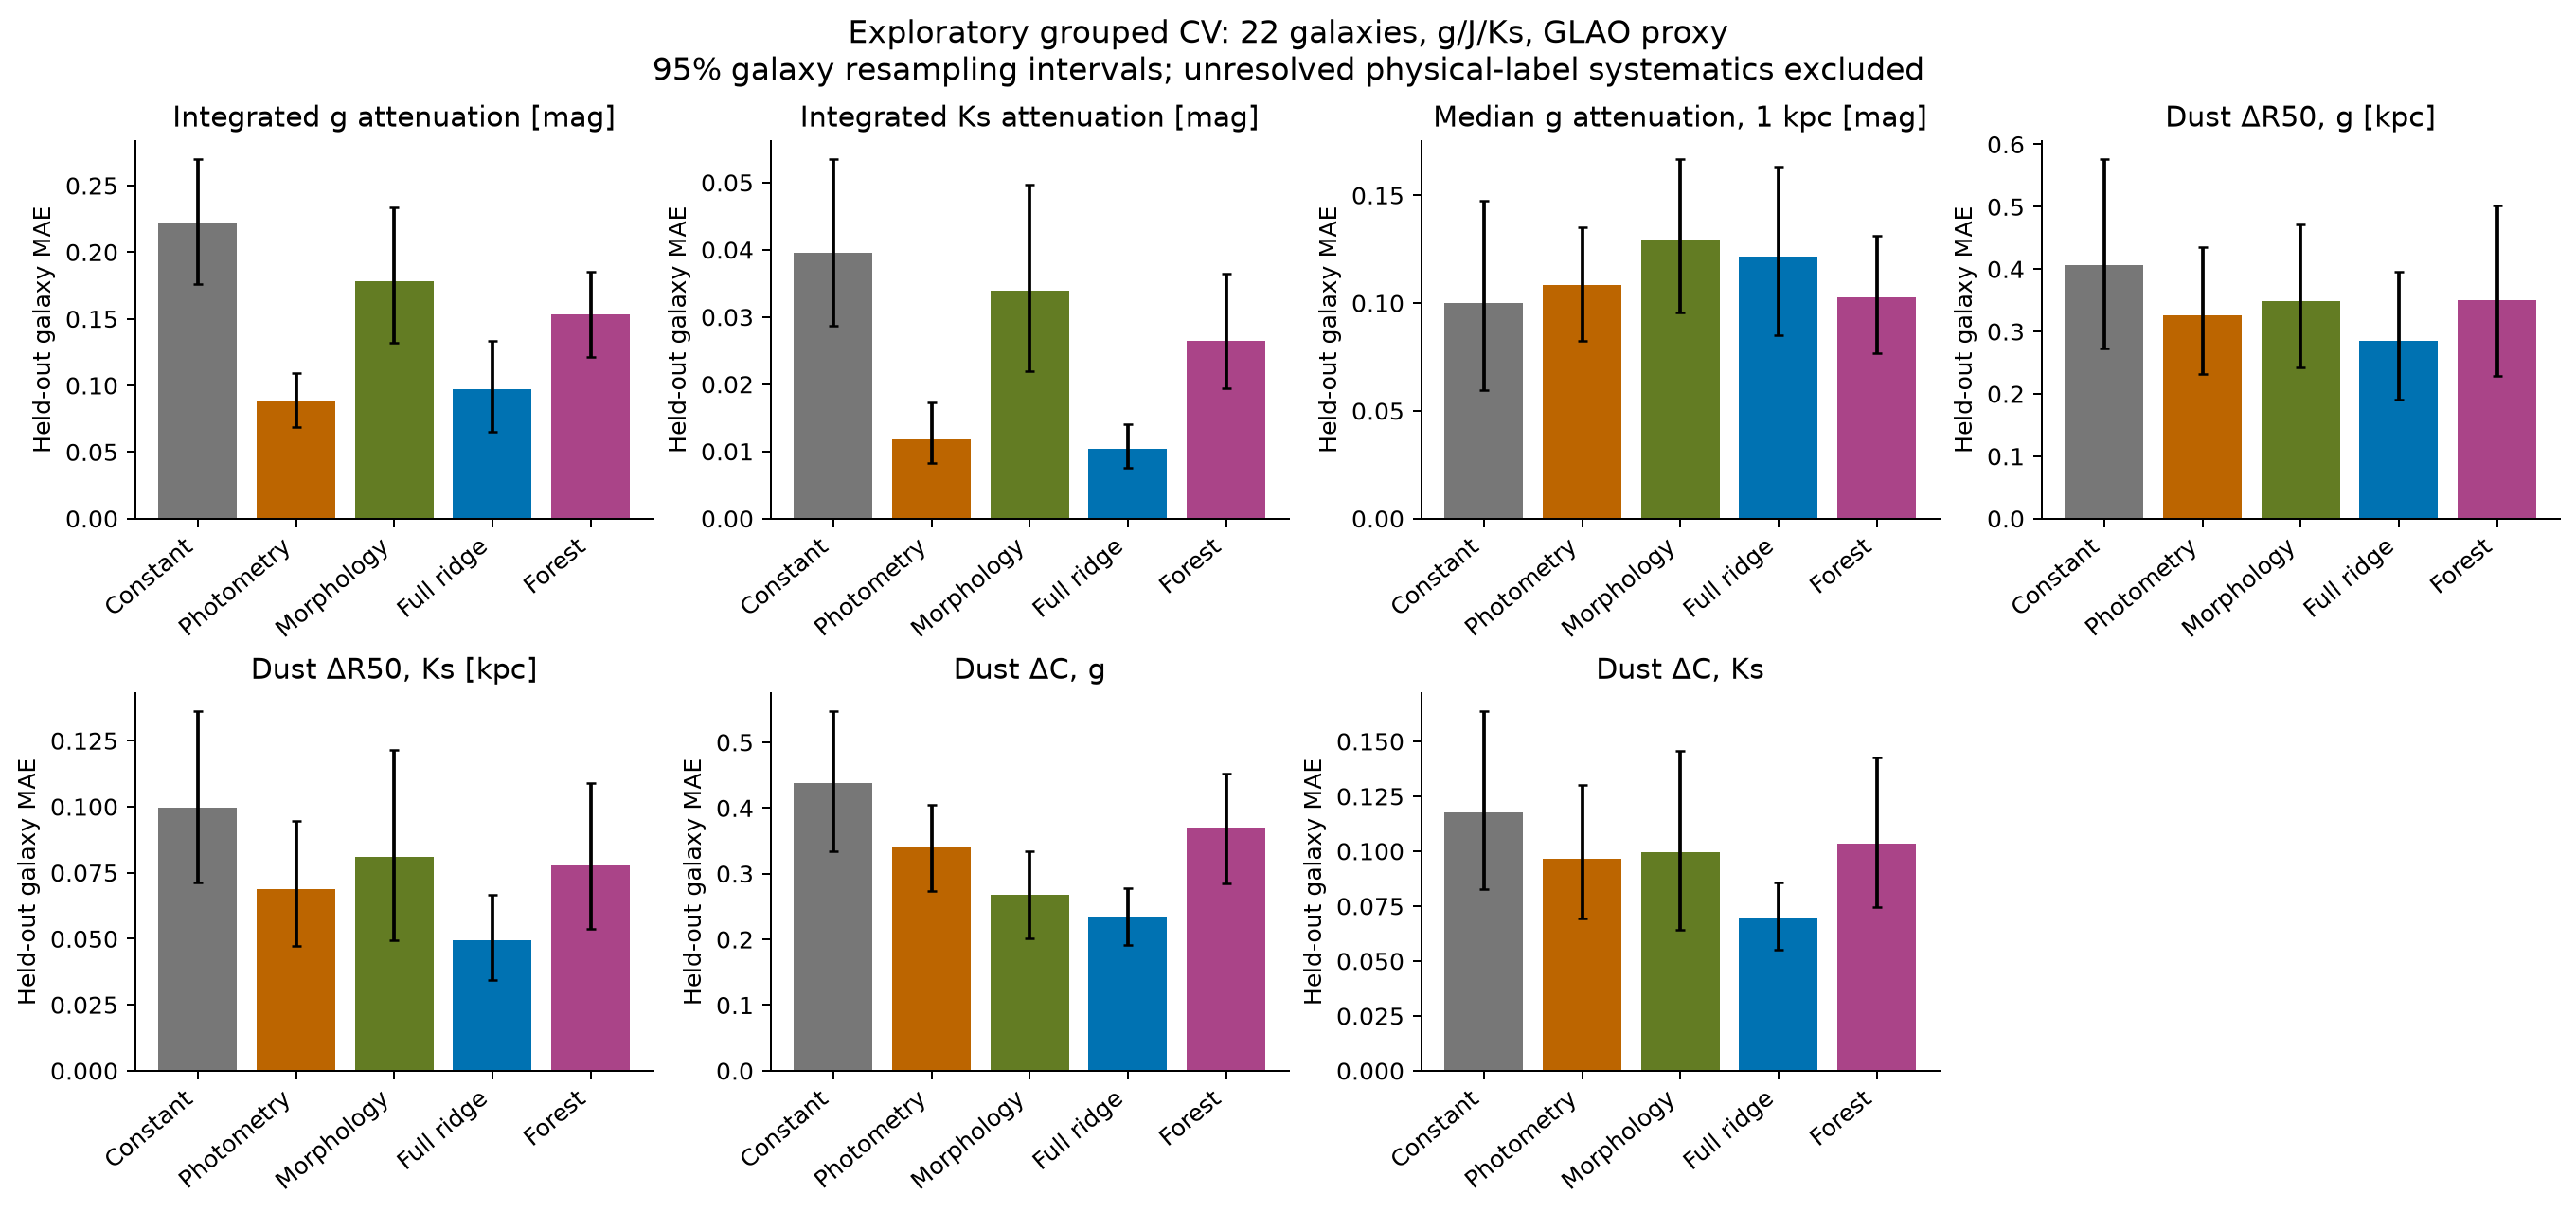

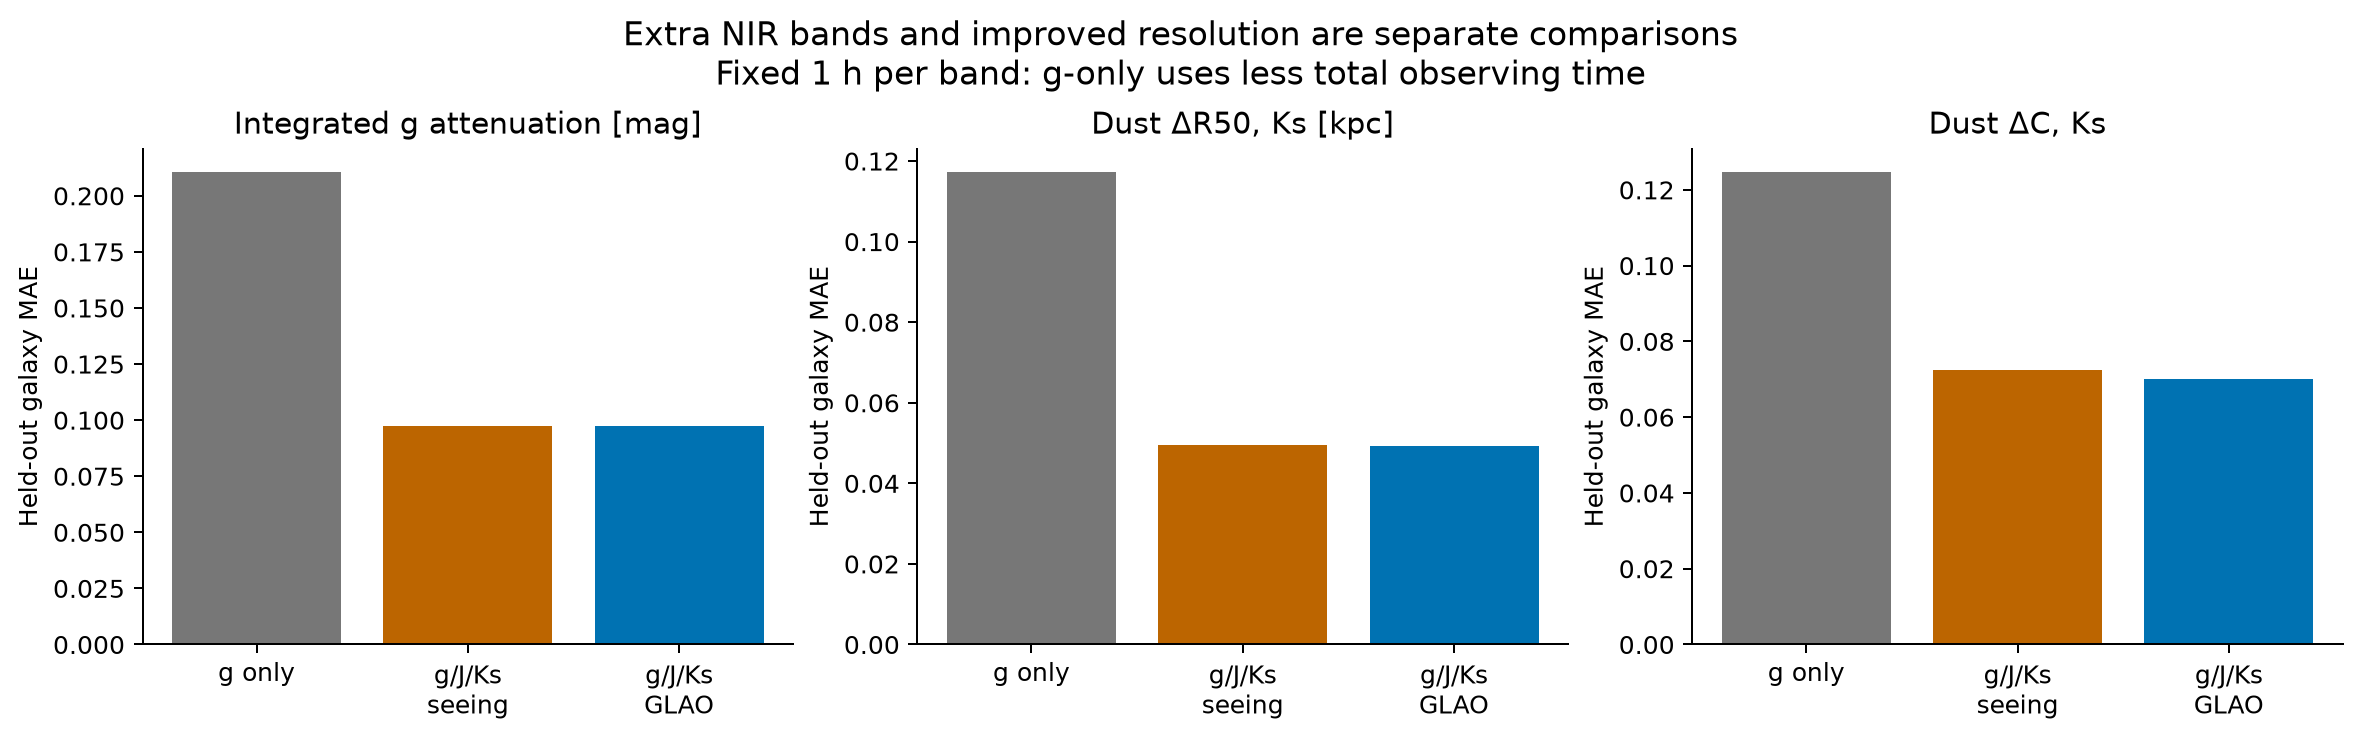

In [5]:
summary=pd.read_csv(O/'heldout_summary.csv')
display(summary[(summary.condition=='original_noise') & (summary['mode']=='glao') & (summary.bandset=='g_J_Ks')][['model','target','MAE','MAE_CI_low','MAE_CI_high']])
display(Image(filename=str(O/'figures/01_grouped_ML_errors.png')))
display(Image(filename=str(O/'figures/03_extra_bands_vs_resolution.png')))

### Seeing versus GLAO, with noise ablations

Positive paired error reduction favors GLAO. Primary ridge/forest intervals include zero across targets. Noiseless and equal-noise conditions separate spatial transfer from added-noise assumptions.

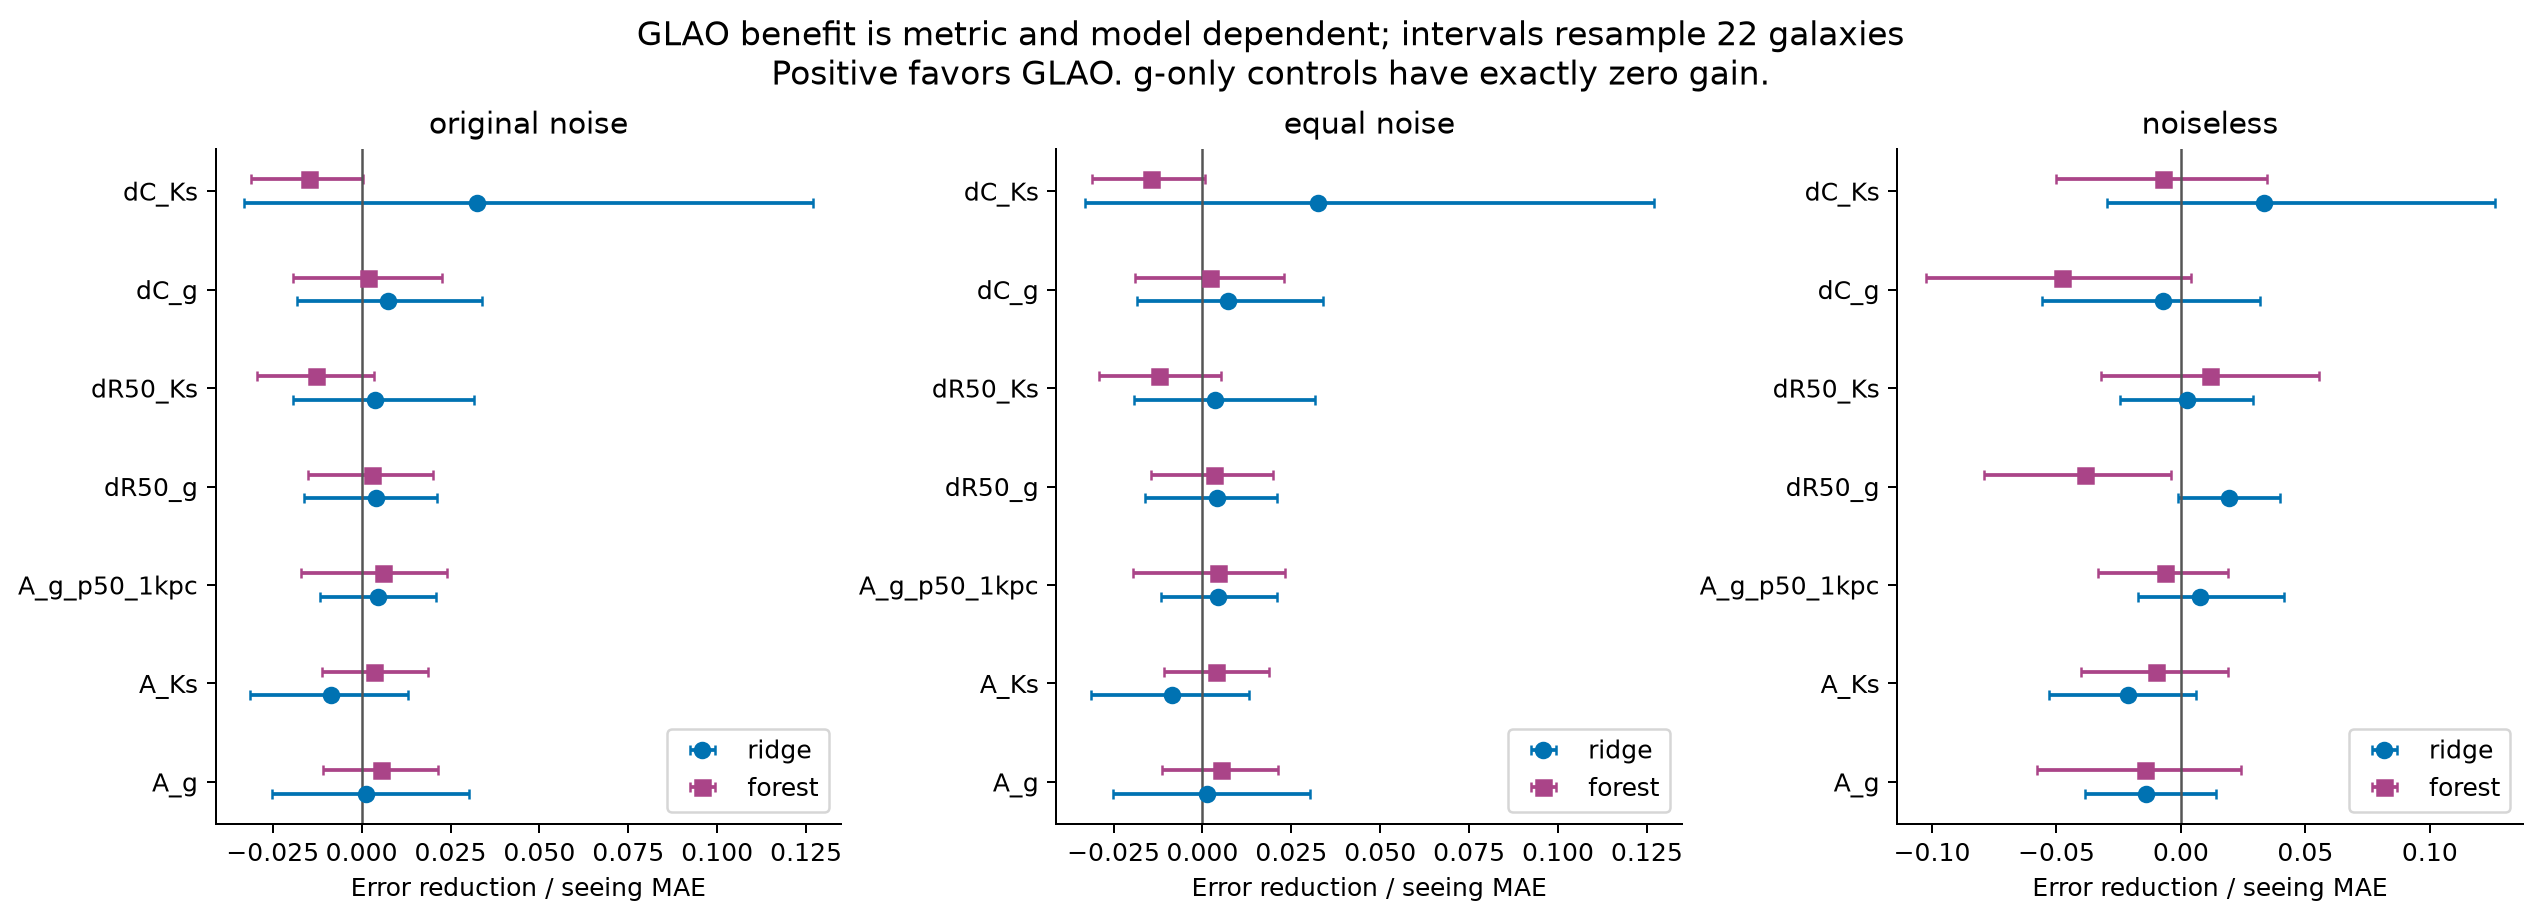

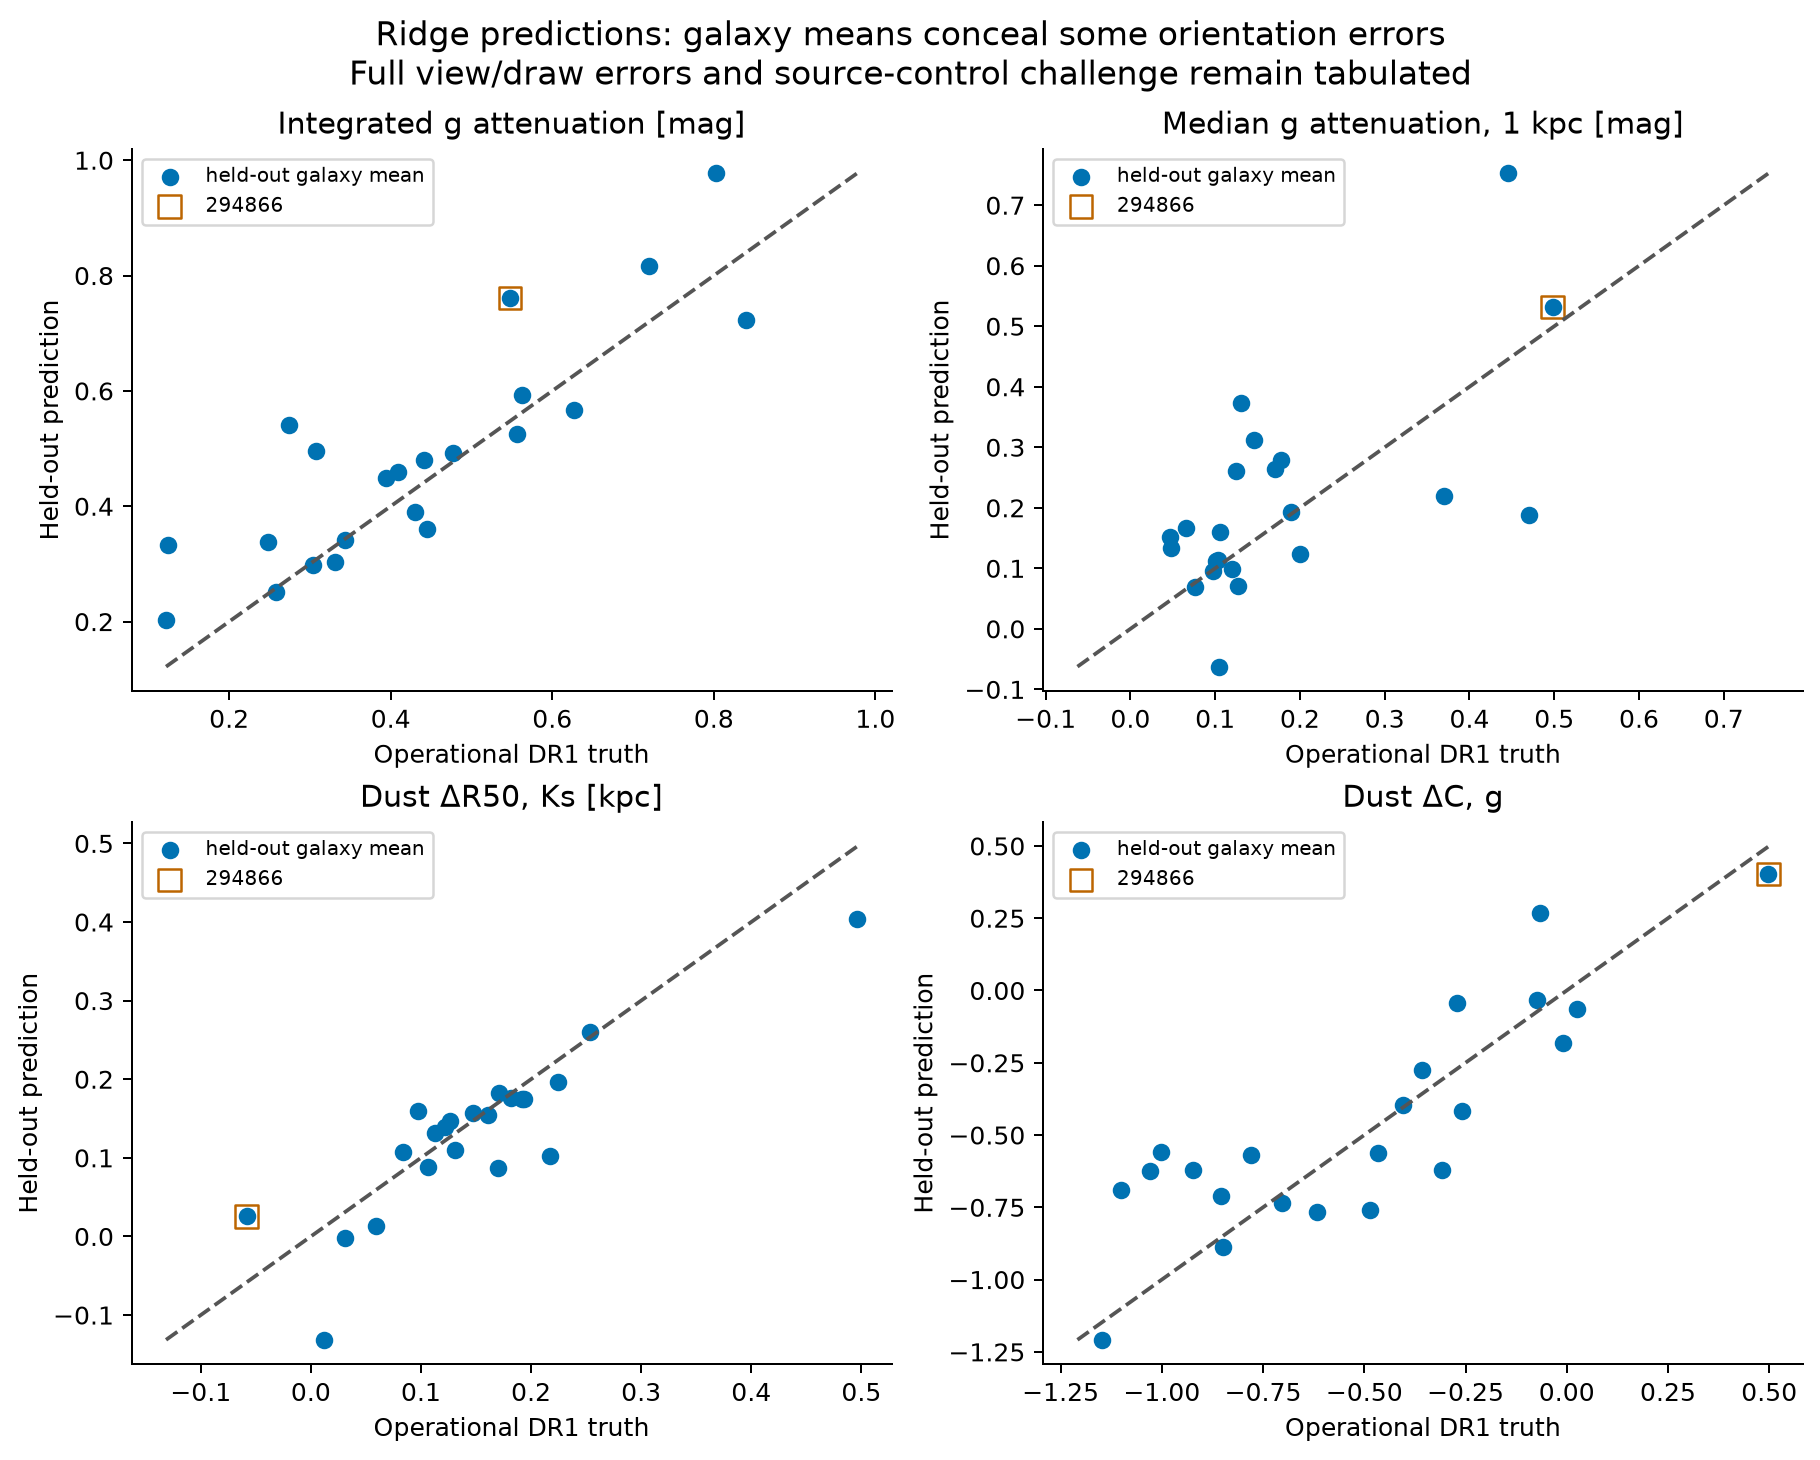

In [6]:
display(Image(filename=str(O/'figures/02_GLAO_ML_ablation.png')))
display(Image(filename=str(O/'figures/04_heldout_predictions.png')))

### Uncertainty, shifted tests and correction

Five calibration galaxies per fold provide coarse nominal80% simultaneous intervals. Empirical undercoverage and source-null failures remain visible. Correction is scored against native clear morphology and leaves PSF/noise error; constant corrections also help.

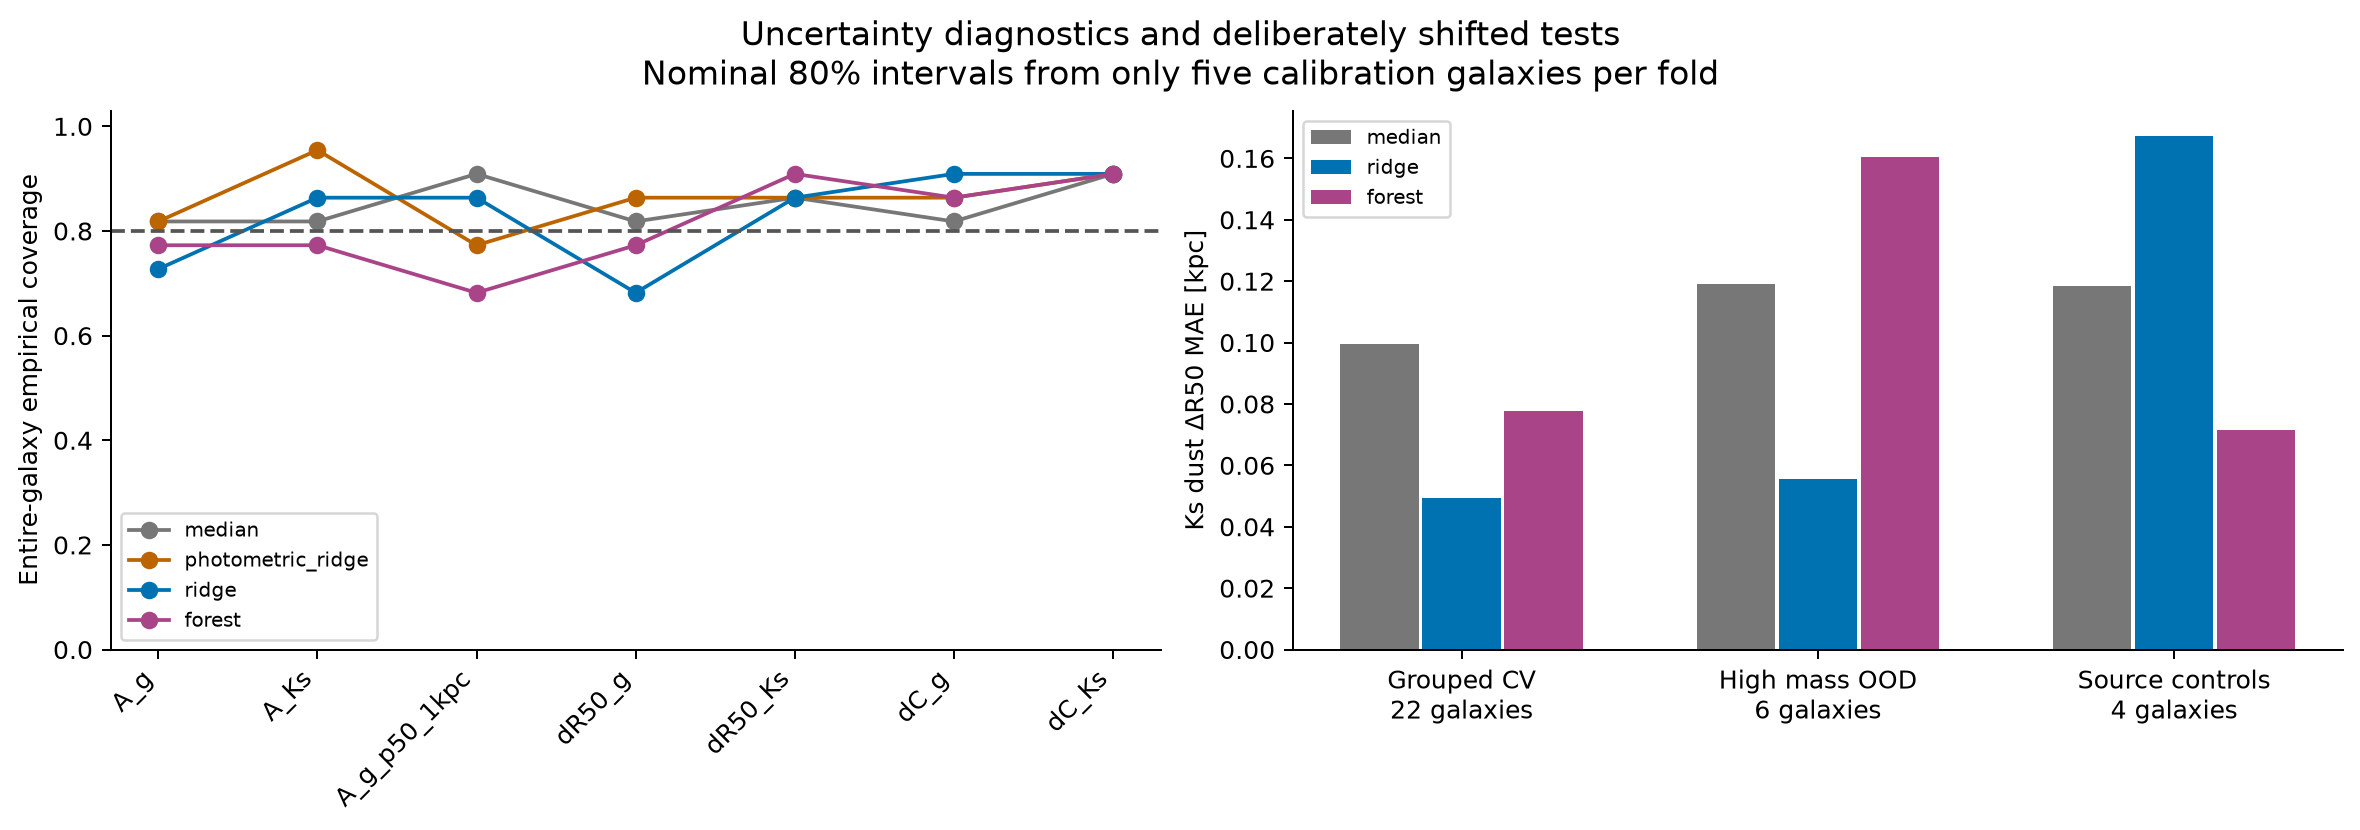

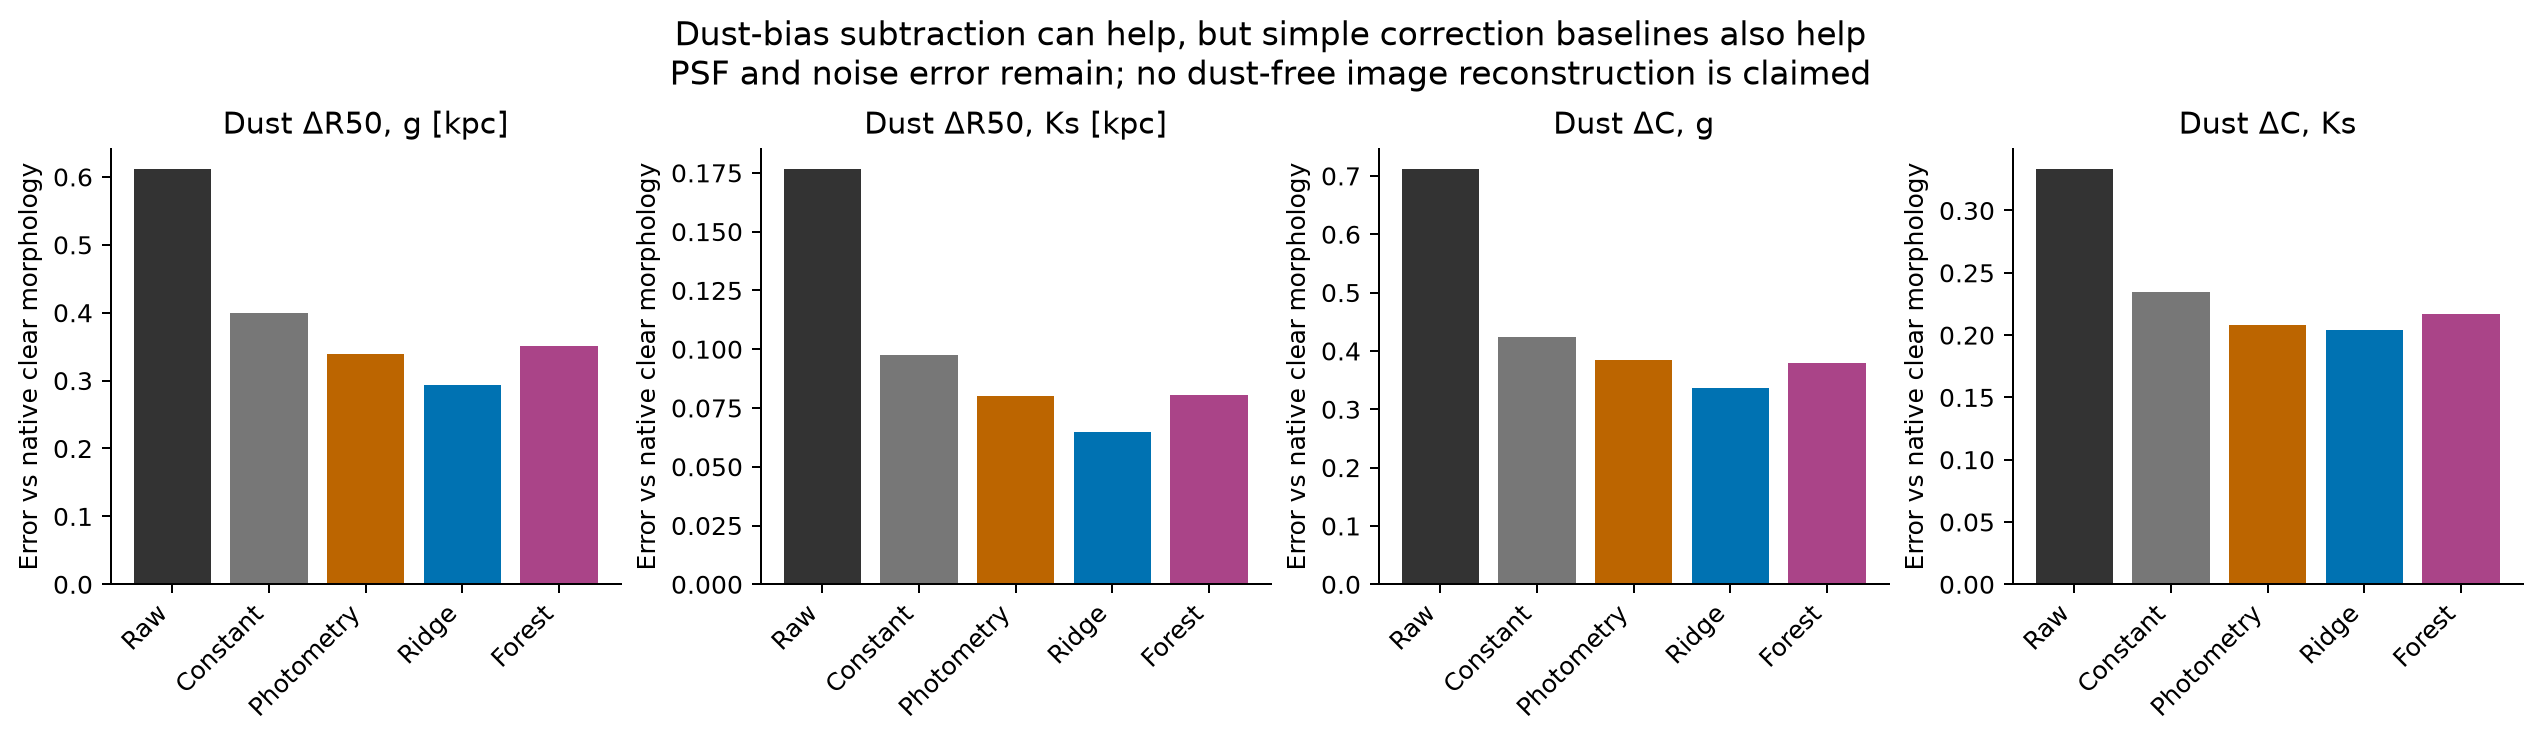

,target,n_control_galaxies,median_control_value,median_control_absolute_value,maximum_control_absolute_value,interpretation
0,A_g,4,0.121383,0.121383,0.123917,Unresolved empirical source-product residual s...
1,A_Ks,4,0.020481,0.020481,0.021591,Unresolved empirical source-product residual s...
2,A_g_p50_1kpc,4,0.111150,0.111150,0.118867,Unresolved empirical source-product residual s...
3,dR50_g,4,0.007832,0.007832,0.031089,Unresolved empirical source-product residual s...
4,dR50_Ks,4,0.011064,0.011064,0.039185,Unresolved empirical source-product residual s...
5,dC_g,4,0.011001,0.013213,0.069286,Unresolved empirical source-product residual s...
6,dC_Ks,4,0.014353,0.016255,0.045964,Unresolved empirical source-product residual s...


,target,alternative_setting,n_galaxies,median_galaxy_mean_absolute_label_change,mean_galaxy_mean_absolute_label_change,maximum_galaxy_mean_absolute_label_change,interpretation
0,dR50_Ks,20,22,0.032871,0.038612,0.170505,Different aperture/center definitions are syst...
1,dC_Ks,20,22,0.027189,0.032378,0.062407,Different aperture/center definitions are syst...
2,dR50_Ks,30,22,0.049406,0.058631,0.335606,Different aperture/center definitions are syst...
3,dC_Ks,30,22,0.028876,0.035196,0.088732,Different aperture/center definitions are syst...
4,dR50_Ks,offset-0.2,22,0.004884,0.006030,0.015298,Different aperture/center definitions are syst...
5,dC_Ks,offset-0.2,22,0.025156,0.033191,0.102487,Different aperture/center definitions are syst...
6,dR50_Ks,offset0.2,22,0.005155,0.006139,0.015040,Different aperture/center definitions are syst...
7,dC_Ks,offset0.2,22,0.026382,0.038003,0.182736,Different aperture/center definitions are syst...
8,dR50_g,20,22,0.179858,0.224192,0.889670,Different aperture/center definitions are syst...
9,dC_g,20,22,0.050915,0.113885,0.651304,Different aperture/center definitions are syst...


In [7]:
display(Image(filename=str(O/'figures/05_uncertainty_and_OOD.png')))
display(Image(filename=str(O/'figures/06_morphology_correction.png')))
display(pd.read_csv(O/'source_null_label_audit.csv'))
display(pd.read_csv(O/'label_policy_uncertainty_summary.csv'))

### HAWK-I empirical constraints and conditional sensitivity

Processed official reduced science/variance/confidence cutouts. Real HAWK-I widths are not ULTIMATE resolution. The post-protocol wing/local-covariance stress is saved separately and does not reproduce all real larger-scale sky noise.

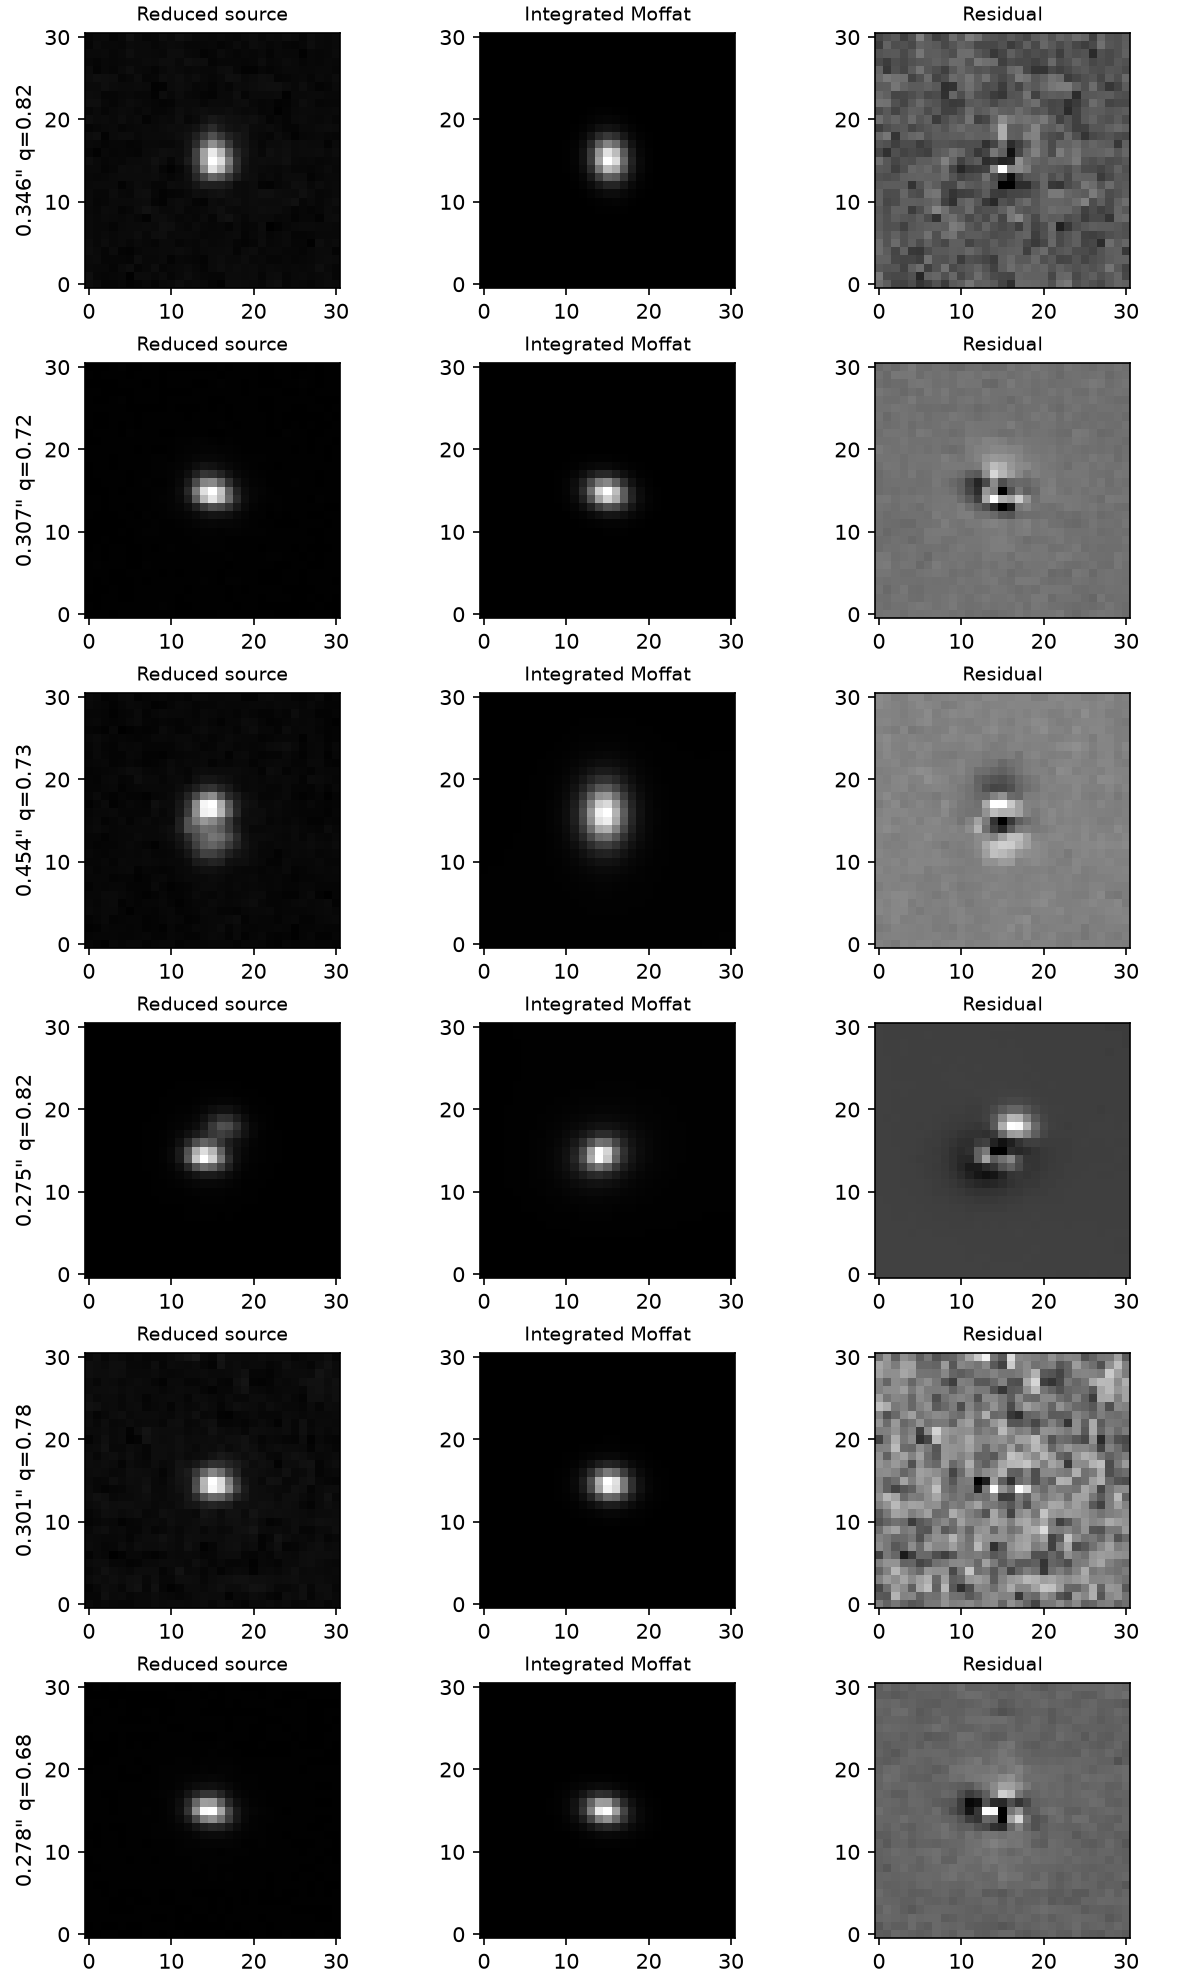

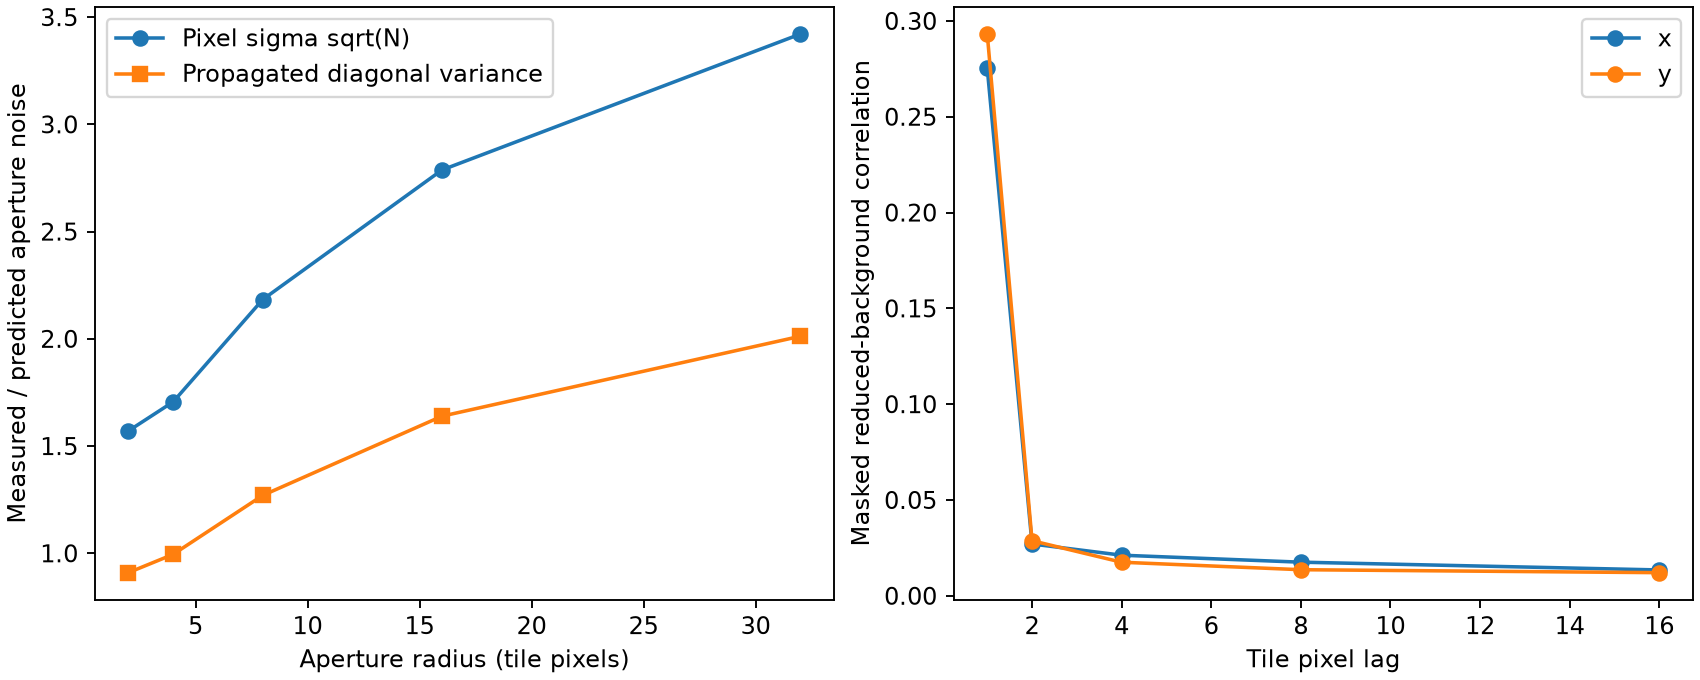

,case,model,target,seeing_MAE,glao_MAE,mean_gain,CI_low,CI_high,n_galaxies
0,Ks_empirical_wings,forest,A_Ks,0.027916,0.026570,0.001347,0.000156,0.002781,22
1,Ks_empirical_wings,forest,A_g,0.159544,0.153280,0.006264,-0.002137,0.016799,22
2,Ks_empirical_wings,forest,A_g_p50_1kpc,0.106626,0.102184,0.004442,-0.001090,0.012596,22
3,Ks_empirical_wings,forest,dC_Ks,0.101822,0.100859,0.000963,-0.002741,0.004552,22
4,Ks_empirical_wings,forest,dC_g,0.380721,0.368192,0.012528,-0.002174,0.029172,22
5,Ks_empirical_wings,forest,dR50_Ks,0.076243,0.077154,-0.000911,-0.003003,0.001091,22
6,Ks_empirical_wings,forest,dR50_g,0.368518,0.349920,0.018598,0.004959,0.036366,22
7,Ks_empirical_wings,ridge,A_Ks,0.010260,0.010357,-0.000097,-0.000324,0.000114,22
8,Ks_empirical_wings,ridge,A_g,0.097571,0.097246,0.000324,-0.002030,0.002797,22
9,Ks_empirical_wings,ridge,A_g_p50_1kpc,0.121784,0.121425,0.000359,-0.001091,0.001815,22


{'scope': 'Exploratory post-protocol sensitivity only, not calibrated ULTIMATE or HAWK-I forecast',
 'measured_Ks_beta': 4.752960293795975,
 'Ks_D50': 'Retain provisional seeing0.588 and GLAO0.390arcsec; do not substitute measured HAWK-I FWHM',
 'innovation_variance': 0.9981478398206823,
 'empirical_rho_x': 0.2752555,
 'simulated_rho_x': 0.2751679635148723,
 'empirical_rho_y': 0.29317406,
 'simulated_rho_y': 0.2933595071500118,
 'limitation': 'Only local pixel covariance and circularized wings; real large-aperture excess noise, anisotropy/field variation not captured',
 'noise_amplitude': 'Provisional simulated electron variance; no transfer of raw ADU amplitudes',
 'training': 'Same frozen grouped folds, no hyperparameter tuning; refit sensitivity models'}

In [8]:
display(Image(filename=str(O/'hawki/reduced_fit_inspection.png')))
display(Image(filename=str(O/'hawki/reduced_noise.png')))
display(pd.read_csv(O/'empirical_stress_summary.csv'))
display(json.loads((O/'empirical_stress_assumptions.json').read_text()))

### Information-boundary tests

Test-truth perturbation must not change predictions/intervals. The120-galaxy final set remains absent from this CV.

In [9]:
import unittest, test_ml_integrity
result=unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromModule(test_ml_integrity))
assert result.wasSuccessful()
print('Integrity tests passed:',result.testsRun)

.

.

.

.

----------------------------------------------------------------------
Ran 4 tests in 0.187s

OK


Integrity tests passed: 4


## Takeaways

The report separates prediction of operational simulation labels, physical attribution, conditional instrument comparisons and future final-sample evaluation.

In [10]:
display(Markdown((O/'scientific_report.md').read_text()))

# Preliminary ML feasibility: effective attenuation and morphology correction

Executed on 2026-10-27 in the existing `phd` environment. Original results/data are
read-only. All new outputs are confined here, apart from the separately isolated
authorized DR1 expansion archives. No large neural network or geometry classifier.

## Scientific conclusion

**GO for a larger, carefully validated surrogate-prediction study; no robust GLAO
ML advantage is established by this preliminary benchmark.** Observable g/J/Ks
features predict several operational DR1 paired quantities better than a constant
baseline. Much of the attenuation prediction is already captured by simple
integrated colours. Adding spatial features helps some morphology-bias targets,
but does not improve every target. The median 1-kpc effective-attenuation statistic
is an unsuccessful case: full ridge and forest do not beat the constant baseline.

These are simulation-product prediction results, **not verified physical dust
geometry or dust-mass recovery**. Unknown source-product systematics remain after
excluding the four zero-projected-dust controls. A numerical error smaller than
their residual scale is not an equally precise physical attenuation measurement.

## What was actually executed

- Reused the verified images of all26 previously explored galaxies, five views
  each. Constructed130 seven-target label records and6240 observable feature rows
  across two PSF strategies, three noise conditions and eight draws. Noiseless
  rows are repeated identically eight times to preserve row weighting and forest
  leaf-size conventions; they are not independent noise realizations.
- Excluded four zero-projected-dust objects from every fit/calibration. They are
  a separate challenge set, not relabelled as zero attenuation. The positive-dust
  zero-SFR object is retained: zero SFR is not a dust-free definition.
- Five fixed galaxy folds over the22 remaining objects. In each fold, five other
  galaxies calibrate intervals,12 or13 fit the model, and4 or5 are outer test
  galaxies. All views/draws stay with a galaxy. Hyperparameters were fixed, not
  chosen from these outer tests. This is exploratory development CV; no object
  in the new final-evaluation partition was scientifically inspected or fitted.
- Compared training median, photometric ridge, morphology ridge, full ridge and
  a shallow80-tree random forest. Fitting-only imputers/scalers and target
  standardization prevent test information entering preprocessing. Ridge alpha10;
  forest depth4/minimum20rows per leaf; forest uses shared standardized multi-target
  splits. `train_test_provenance.json` lists exact features and split IDs.
- Tested noiseless, original exact-moment noise, and equal noise across strategies.
  Equal-noise pixels use the maximum seeing/GLAO variance with paired innovations.
  This separates the PSF comparison from differing added-noise variances.
- Re-rendered original dusty noise properties match the previous verified tables.
  g-only features and predictions are identical between strategies. Four integrity
  tests include disjoint galaxy roles, observable feature allowlists and a direct
  perturbation showing test truth cannot change predictions or interval widths.

## Inputs and target definitions

Models receive only measured dusty-image properties: aperture Jy flux, R50,
concentration, raw asymmetry, apparent q, central light fraction, integrated colours
and inner/outer colour gradients. They receive no clear map, physical dust map,
stellar mass/SFR, true inclination, galaxy ID, target or noise-realization identifier.
IDs are used only for partitioning/scoring. Total flux is an observable, but at
one fixed distance it can exploit a sample-specific luminosity prior; success
does not demonstrate population-independent dust inference.

`A_g` and `A_Ks` are -2.5log10(sum dusty/sum clear) within the fixed12-kpc aperture.
`A_g_p50_1kpc` is the median -2.5log10(smoothed dusty/smoothed clear), using1-kpc
Gaussian FWHM, positive finite flux, clear >1e-4 of its smoothed peak and R<12kpc.
Negative valid effective attenuation is retained. These are effective broadband
statistics, not optical depth. `dR50` and `dC` use native dusty-minus-clear pairs,
with C=5log10(R80/R20). Known center/distance and fixed circular aperture are
idealizations inherited from the validated study. No segmentation/orientation
criterion was tuned to improve held-out errors.

## Held-out performance

Equal-galaxy MAE, original noise, GLAO proxy, g/J/Ks inputs. Attenuation units are
mag; R50 differences are kpc; concentration is dimensionless. Every entry has22
held-out galaxy contributions; views/pixels/noise draws are not independent objects.

| Operational target | Constant | Photometry | Morphology | Full ridge | Forest |
| --- | --- | --- | --- | --- | --- |
| A_g | 0.22122 | 0.08877 | 0.17844 | 0.09720 | 0.15304 |
| A_Ks | 0.03950 | 0.01182 | 0.03385 | 0.01038 | 0.02643 |
| A_g_p50_1kpc | 0.09999 | 0.10846 | 0.12927 | 0.12155 | 0.10267 |
| dR50_g | 0.40651 | 0.32630 | 0.34899 | 0.28420 | 0.34951 |
| dR50_Ks | 0.09961 | 0.06881 | 0.08093 | 0.04928 | 0.07779 |
| dC_g | 0.43797 | 0.33929 | 0.26849 | 0.23454 | 0.36960 |
| dC_Ks | 0.11742 | 0.09664 | 0.09948 | 0.06999 | 0.10328 |

The photometric baseline uses g flux plus integrated colours, without spatial
morphology features. It beats full ridge for integrated g attenuation (0.08877 versus
0.09720mag). Full ridge improves Ks R50-bias prediction over the colour baseline
(0.04928 versus0.06881kpc). These comparisons use the same folds; all signed paired
effects and galaxy-resampling intervals are in `paired_model_comparisons.csv`.
They are not a model-selection exercise identifying a final deployable model.

## Does GLAO help ML?

Predefined gain is seeing MAE minus GLAO MAE, averaged within galaxies first.
The full-ridge primary comparison is:

| Target | Seeing MAE | GLAO MAE | Gain [95% galaxy resampling] |
| --- | --- | --- | --- |
| A_g | 0.09732 | 0.09720 | +0.00012 [-0.00244, +0.00295] |
| A_Ks | 0.01029 | 0.01038 | -0.00009 [-0.00032, +0.00013] |
| A_g_p50_1kpc | 0.12210 | 0.12155 | +0.00055 [-0.00144, +0.00256] |
| dR50_g | 0.28534 | 0.28420 | +0.00114 [-0.00459, +0.00602] |
| dR50_Ks | 0.04946 | 0.04928 | +0.00018 [-0.00095, +0.00157] |
| dC_g | 0.23627 | 0.23454 | +0.00173 [-0.00432, +0.00801] |
| dC_Ks | 0.07234 | 0.06999 | +0.00235 [-0.00239, +0.00918] |

**Every full-ridge primary interval includes zero.** Forest primary intervals
also include zero for all seven targets. Extra NIR information shows larger
improvements than the PSF change. g-only versus g/J/Ks uses1hour per band, hence
different total telescope allocations (1 versus3hours before overheads); it is
an information ablation, not an equal-time efficiency forecast.

The noiseless and equal-noise comparisons retain weak/mixed resolution effects;
there is no universal monotonic benefit. The noiseless forest g R50 target even
worsens under the narrower NIR PSF. No multiple-testing-adjusted significant
advantage is claimed. The5000-resample intervals condition on the fitted models,
folds and selected galaxies: overlapping training sets and training-set uncertainty
are not fully captured. The sample is not volume representative.

## Morphology correction

Subtract predicted native dust bias from the observed dusty morphology and score
against native clear morphology. This tests whether a numerical correction helps;
the PSF/noise error remains, and no clear image is reconstructed. Galaxy-mean MAEs:

| Target | Uncorrected error | Constant correction | Photometric correction | Ridge correction |
| --- | --- | --- | --- | --- |
| dR50_g | 0.61110 | 0.39896 | 0.33891 | 0.29425 |
| dR50_Ks | 0.17648 | 0.09768 | 0.08015 | 0.06485 |
| dC_g | 0.71121 | 0.42306 | 0.38525 | 0.33597 |
| dC_Ks | 0.33300 | 0.23479 | 0.20835 | 0.20434 |

Simple constant correction already helps substantially. Incremental benefit over
that baseline, the colour baseline and all unfavorable galaxies must remain
visible; `correction_summary.csv` reports per-target signs and uncertainty. This
benchmark cannot establish an unbiased correction for arbitrary real galaxies.

## Uncertainty calibration and OOD behavior

Nominal80% split-conformal diagnostic: five calibration-galaxy scores, each the
maximum absolute residual over all its views/draws, give one simultaneous bound
per target. The required finite-sample order is ceil(6*0.8)=5, the maximum score.
Full ridge shows the following empirical entire-galaxy coverage:

| Target | Covered entire galaxies /22 | Mean interval width |
| --- | --- | --- |
| A_g | 16/22 | 0.5246 |
| A_Ks | 19/22 | 0.1169 |
| A_g_p50_1kpc | 19/22 | 1.0642 |
| dR50_g | 15/22 | 1.5068 |
| dR50_Ks | 19/22 | 0.4016 |
| dC_g | 20/22 | 2.0665 |
| dC_Ks | 20/22 | 0.6281 |

The g R50 target covers only15/22 galaxies, and integrated g attenuation16/22;
this is not demonstrated80% population calibration. Intervals are often broad.
Finite selected samples, OOD objects and unknown physical-label errors prevent
unqualified coverage guarantees. Noise-draw prediction SD is separately saved;
it is not substituted for between-galaxy or model uncertainty. The method follows
the split-calibration framework described by
[Angelopoulos & Bates](https://arxiv.org/abs/2107.07511); its exchangeability premise
is not established for this selected simulation sample.

The deliberate high-mass-quartile challenge holds out6 galaxies and fits only
the16 lower-mass objects. Full-ridge g concentration-bias MAE worsens to0.7675,
versus0.2345 in grouped CV; Ks R50 MAE is0.0554 versus0.0493. The four source-null
controls give Ks R50-bias MAE0.1672, much worse than CV. Physical metadata define
these diagnostics but never enter X. `OOD_summary.csv`, exact split IDs and
observable-space nearest-training distances preserve the failure cases.

## Physical-label and aperture uncertainty

The four controls have median integrated pair residuals0.1214mag in g and0.0205mag
in Ks despite zero projected field dust. Their maximum view-level |dR50| values
are0.0311 and0.0392kpc. No universal offset is subtracted. These controls are a
warning, not a validated transferable error distribution. Excluding them is
insufficient to prove the remaining22 labels are physically exact.

Changing the target aperture from12 to30kpc changes the native dust-bias label
by a median galaxy-mean absolute0.2436kpc in g R50 and0.0494kpc in Ks R50 across
the22 fitting-eligible galaxies. These are comparable to ML errors and far larger
than the primary GLAO gains. Center offsets and concentration sensitivities remain
tabulated in `label_policy_uncertainty_summary.csv`; fixed-prediction stress under
alternative definitions is explicitly a task-definition change, not Gaussian
label noise. A stable scientific aperture/segmentation policy is a prerequisite
for interpreting better prediction as better physical correction.

## HAWK-I calibration and empirical sensitivity

Official ESO reduced products and their variance/confidence maps exist for the
same observations. We obtained small target-centered Jan6 science/variance/weight
cutouts (64.18MiB retained;128.36MiB total including a corrected initial cutout),
checked checksums and aligned WCS grids, and executed image-level fits and masked
sky/aperture-noise measurements. Local raw frames are complete for the22 archive
science exposures. Certified calibration associations exist, but local master
calibrations and EsoRex are absent; an unnecessary incomplete raw reduction was
not attempted. See [the empirical calibration report](hawki/hawki_empirical_calibration_report.md).

The103 accepted reduced compact-source candidates have median FWHM0.3166arcsec,
Moffat beta4.753, q0.820 and circularized D50=0.3533arcsec. Candidate/field scatter
and analytic growth-curve extrapolation are explicit; stellar identities and
absolute external astrometric/photometric validation are not assumed. Adjacent
background correlations are0.2753/0.2932. At32pixel aperture radius, noise is3.42
times sigma_pixel sqrt(N), and2.01 times the propagated diagonal-variance prediction.
Thus pixel variance alone is inadequate for larger-scale surface-brightness work.

A small catalogue follow-up finds9 quality-selected stellar matches to2MASS:
median radial offset0.121arcsec (RMS0.169arcsec), and HAWK-I minus colour-transformed
2MASS Ks median-0.0558mag with robust scatter0.1390mag (RMS0.2429mag, outlier retained).
This recomputes consistency using the same reference system that the pipeline
used; it is not an independent astrometric/photometric calibration or a precision
zeropoint validation. Exact matching, aperture correction and colour conventions
are documented in the HAWK-I report and saved match table. The actual associated
PHOTCAL table uses0.03J+0.97Ks; the release description instead prints an H-based
term. Both residual calculations are retained and the actual calibration-file
formula is used here. The nine quality stellar matches have median FWHM0.2935arcsec
and beta3.7415, illustrating selection sensitivity relative to all103 compact
sources. The executed empirical stress retains its recorded full-sample beta4.753;
it is not silently retuned to the smaller stellar subset.

An executed **post-protocol** sensitivity uses the measured beta for Ks wings while
retaining provisional seeing/GLAO D50 values. A separate local covariance stress
matches the two adjacent correlations with a unit-variance separable3pixel filter.
Measured longer-scale sky correlations, anisotropy, field variation and larger
aperture noise are not reproduced. It is not a calibrated HAWK-I or ULTIMATE noise
model, and real ADU amplitudes are not transferred to the simulated electron model.
`empirical_stress_summary.csv` records all seven targets/models and retains mixed
or adverse outcomes. Any isolated positive interval is exploratory, with no
multiple-comparison correction; it does not override the frozen primary result.

## Expansion and publication readiness

The exact120-galaxy metadata-only manifest is frozen:86development (all26 old plus
60new),14validation,20completely untouched final evaluation. All94 new archives
passed official DR1 byte-range/size preflight:60,164,124,583bytes (56.032GiB).
The resumable background download is running; consult the timestamped
`expansion/acquisition_status.json` for actual verified counts rather than treating
120 as an achieved download count. Archive CRC/tar checks do not inspect final-test
scientific images. Every transfer chunk enforces100GiB free disk plus safety margin.

Official selection metadata lack dust mass and morphology classes; broad mass/
activity stratification and explicitly qualified gas/size proxies were used.
The selection probabilities and unavailable dimensions are documented, not invented.
No new galaxy image has entered this benchmark. Future validation/final partitions
must stay separate from training, hyperparameter choice, calibration and feature
design; resolve that workflow before opening their labels.

**Workshop-ready with negative and positive results together.** Suggested figures:
01 (baselines),03 (bands versus resolution),05 (coverage/OOD),06 (correction), plus
HAWK-I reduced PSF/noise panels. A safe abstract update is “learning effective
attenuation statistics and morphology corrections from radiative-transfer mocks,”
not unique3D dust geometry. The prior false positives and geometry-model failures
remain unchanged.

**A dedicated paper needs more than this pilot:** complete acquisition, improve
source-product physical-null calibration and aperture robustness, increase the
independent training sample, establish held-out uncertainty/OOD behavior, include
realistic field-dependent PSF/sky/covariance systematics and actual observer-filter
synthetic photometry, then perform one frozen final evaluation. Dust-dependent
morphology itself overlaps the larger
[TNG50-SKIRT atlas morphology study](https://arxiv.org/abs/2605.20886); distinctive
novelty should be validated instrumental transfer and defensible observational
prediction, not rediscovery of an atlas trend. No universal ULTIMATE gain is claimed.
